In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [39]:
df = pd.read_csv("../dataset/Cleaned/Cleaned_Master_Environmental_Impact_Dataset.csv")

In [40]:
df.head()

,Country,City,AQI Value,AQI Category,CO AQI Value,CO AQI Category,Ozone AQI Value,Ozone AQI Category,NO2 AQI Value,NO2 AQI Category,PM2.5 AQI Value,PM2.5 AQI Category
0,Russian Federation,Praskoveya,51,Moderate,1,Good,36,Good,0,Good,51,Moderate
1,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good
2,Italy,Priolo Gargallo,66,Moderate,1,Good,39,Good,2,Good,66,Moderate
3,Poland,Przasnysz,34,Good,1,Good,34,Good,0,Good,20,Good
4,France,Punaauia,22,Good,0,Good,22,Good,0,Good,6,Good


In [41]:
high_aqi = df["AQI Value"].mean() + 2 * df["AQI Value"].std()

df["High_AQI_Flag"] = "Normal"

df.loc[df["AQI Value"] > high_aqi, "High_AQI_Flag"] = "Anomaly"

In [42]:
df["High_AQI_Flag"].value_counts()

High_AQI_Flag
Normal     22707
Anomaly      756
Name: count, dtype: int64

In [43]:
pm25_limit = df["PM2.5 AQI Value"].quantile(0.95)

df["High_PM25_Flag"] = np.where(
    df["PM2.5 AQI Value"] > pm25_limit,
    "Anomaly",
    "Normal"
)

In [44]:
df["High_PM25_Flag"].value_counts()

High_PM25_Flag
Normal     22301
Anomaly     1162
Name: count, dtype: int64

In [45]:
no2_limit = df["NO2 AQI Value"].quantile(0.95)

df["High_NO2_Flag"] = np.where(
    df["NO2 AQI Value"] > no2_limit,
    "Anomaly",
    "Normal"
)

In [46]:
co_limit = df["CO AQI Value"].quantile(0.95)

df["High_CO_Flag"] = np.where(
    df["CO AQI Value"] > co_limit,
    "Anomaly",
    "Normal"
)

In [47]:
flag_columns = [
    "High_AQI_Flag",
    "High_PM25_Flag",
    "High_NO2_Flag",
    "High_CO_Flag"
]

df["Anomaly_Score"] = (
    (df[flag_columns] == "Anomaly")
    .sum(axis=1)
)

In [48]:
df[["City", "Country", "Anomaly_Score"]].head()

,City,Country,Anomaly_Score
0,Praskoveya,Russian Federation,0
1,Presidente Dutra,Brazil,0
2,Priolo Gargallo,Italy,0
3,Przasnysz,Poland,0
4,Punaauia,France,0


In [49]:
top_anomalies = (
    df.sort_values("Anomaly_Score", ascending=False)
      .head(10)
)

top_anomalies[
    ["City", "Country", "AQI Value", "Anomaly_Score"]
]

,City,Country,AQI Value,Anomaly_Score
11221,Xiaoyi,China,206,4
17470,Xian,China,307,4
8835,Lampa,Chile,358,4
11867,Chengdu,China,386,4
2056,Brakpan,South Africa,236,4
10102,Buin,Chile,245,4
4627,Baidyabati,India,225,4
9685,Rustenburg,South Africa,248,4
4643,Bekasi,Indonesia,193,4
13187,Tembisa,South Africa,219,4


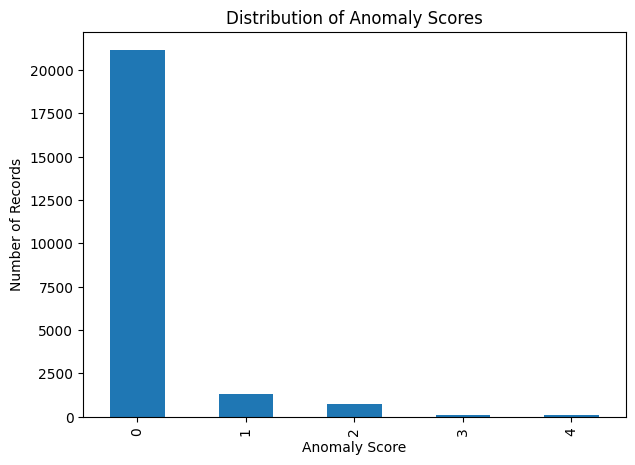

In [50]:
plt.figure(figsize=(7,5))

df["Anomaly_Score"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Anomaly Scores")
plt.xlabel("Anomaly Score")
plt.ylabel("Number of Records")

plt.show()

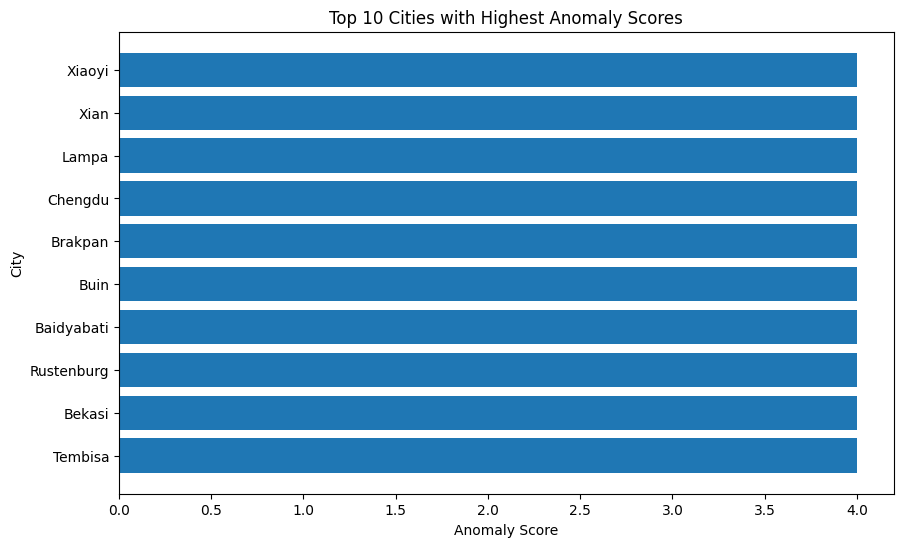

In [51]:
plt.figure(figsize=(10,6))

plt.barh(
    top_anomalies["City"],
    top_anomalies["Anomaly_Score"]
)

plt.title("Top 10 Cities with Highest Anomaly Scores")
plt.xlabel("Anomaly Score")
plt.ylabel("City")

plt.gca().invert_yaxis()

plt.show()

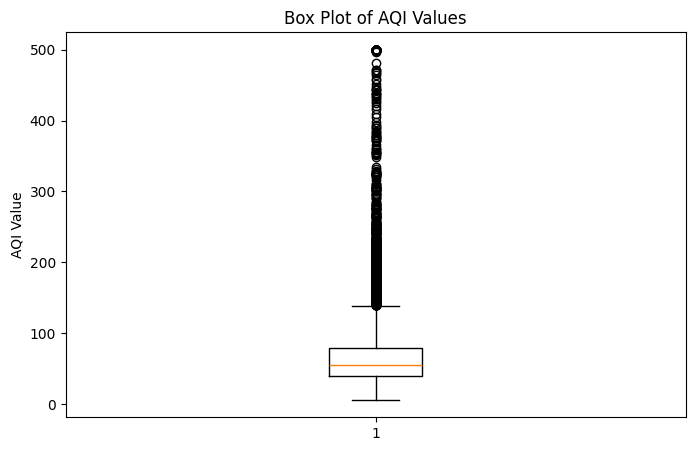

In [52]:
plt.figure(figsize=(8,5))

plt.boxplot(df["AQI Value"])

plt.title("Box Plot of AQI Values")
plt.ylabel("AQI Value")

plt.show()

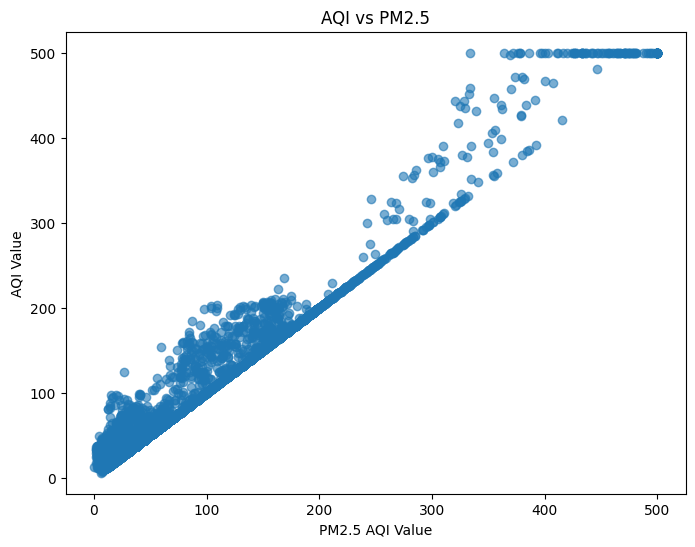

In [53]:
plt.figure(figsize=(8,6))

plt.scatter(
    df["PM2.5 AQI Value"],
    df["AQI Value"],
    alpha=0.6
)

plt.xlabel("PM2.5 AQI Value")
plt.ylabel("AQI Value")
plt.title("AQI vs PM2.5")

plt.show()

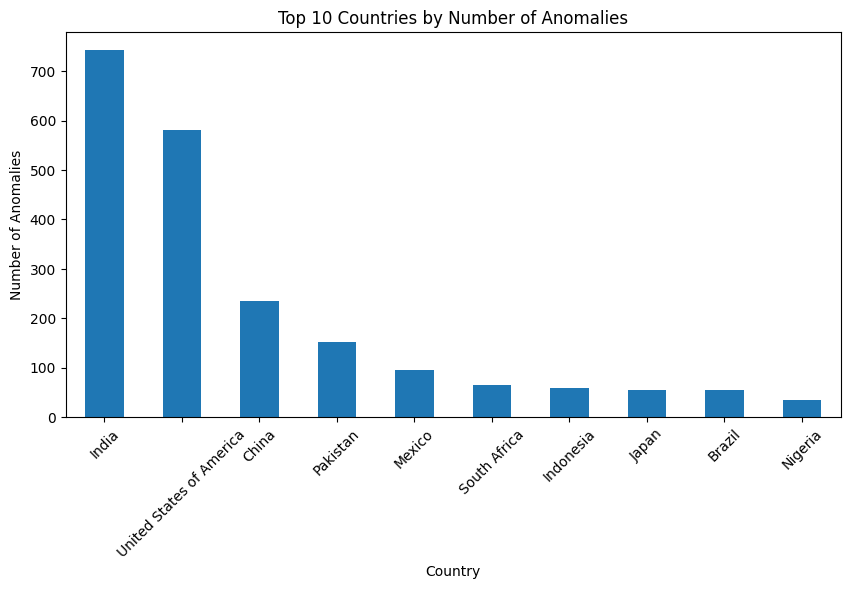

In [ ]:
country_anomalies = (
    df[df["Anomaly_Score"] > 0]
    .groupby("Country")
    .size()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10,5))

country_anomalies.plot(kind="bar")

plt.title("Top 10 Countries by Number of Anomalies")
plt.xlabel("Country")
plt.ylabel("Number of Anomalies")

plt.xticks(rotation=45)

plt.show()

In [55]:
print("Total Records:", len(df))
print("Records with Anomalies:", (df["Anomaly_Score"] > 0).sum())
print("Maximum Anomaly Score:", df["Anomaly_Score"].max())

Total Records: 23463
Records with Anomalies: 2321
Maximum Anomaly Score: 4


# Conclusion

- Rule-based anomaly detection was applied using AQI, PM2.5, NO2, and CO values.
- An anomaly score was calculated for each record based on the number of triggered flags.
- The cities and countries with the highest anomaly scores were identified.
- Box plots and scatter plots highlighted unusual pollution patterns and outliers.
- The analysis can help environmental authorities prioritize regions for detailed monitoring and pollution-control measures.